# Ejercicios de representación de texto (embeddings)

Karla Maria Monroy Alvarez - 263164

Procesamiento de Lenguaje Natural

# Preprocesamiento del corpus

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
import unicodedata

sns.set_style('whitegrid')

# Cargar datos
df = pd.read_csv('emdeddings_dataset.csv')
print('shape', df.shape, 'columns', df.columns.tolist())
text_col = 'frase' if 'frase' in df.columns else df.columns[0]

# Preprocesamiento básico: minúsculas y eliminación de caracteres no alfabéticos
corpus = df[text_col].astype(str).fillna('').str.lower()
corpus = corpus.str.replace(r'[^a-záéíóúñü\s]', '', regex=True)
corpus = corpus.str.replace(r'\s+', ' ', regex=True).str.strip()
print('Ejemplos de frases preprocesadas:', corpus.head(5).tolist())

shape (148, 1) columns ['frase']
Ejemplos de frases preprocesadas: ['la ciberseguridad protege la información digital', 'la inteligencia artificial transforma múltiples industrias', 'el baloncesto combina velocidad técnica y trabajo en equipo', 'el hardware y el software son complementarios en la computación', 'la democracia permite la participación ciudadana en decisiones']


# Modelo

In [3]:
# Ejemplo funcional con SentenceTransformer + t-SNE + clusters
from sentence_transformers import SentenceTransformer

# Cargar modelo SBERT en español
model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

# Usar las frases preprocesadas como entradas para embeddings
txt = corpus.tolist()
embeddings = model.encode(txt, show_progress_bar=True, convert_to_numpy=True)

# t-SNE 2D en los embeddings SBERT
X2_sbert = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto').fit_transform(embeddings)

# Clustering KMeans
kmeans_sbert = KMeans(n_clusters=4, random_state=42)
clusters_sbert = kmeans_sbert.fit_predict(X2_sbert)

# Guardar resultados
df_sbert = pd.DataFrame({'frase': df[text_col], 'frase_preproc': corpus, 'x': X2_sbert[:,0], 'y': X2_sbert[:,1], 'cluster': clusters_sbert})
df_sbert.to_csv('tsne_sbert_positions.csv', index=False)
print('Guardado: tsne_sbert_positions.csv')
print('Tamaños de cluster sbert:')
print(df_sbert.cluster.value_counts())



Loading weights: 100%|██████████| 199/199 [00:00<00:00, 965.71it/s]
BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 5/5 [00:00<00:00, 21.70it/s]


Guardado: tsne_sbert_positions.csv
Tamaños de cluster sbert:
cluster
0    48
3    38
2    38
1    24
Name: count, dtype: int64


# Visualización

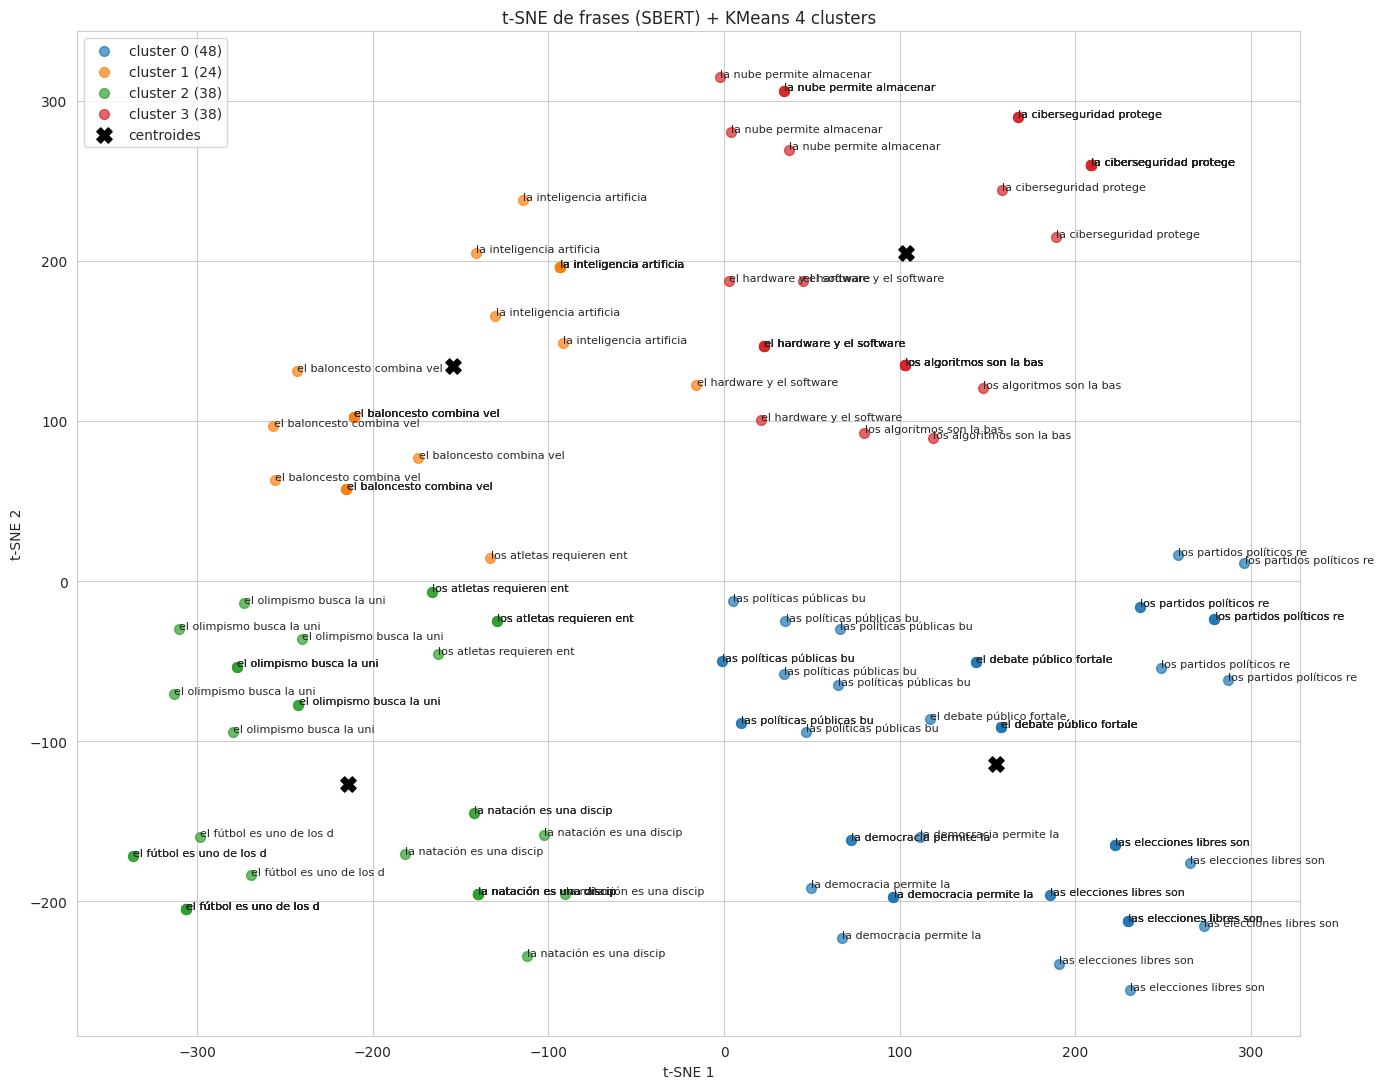

Guardado: tsne_sbert_clusters.png


In [4]:
# Visualización final
plt.figure(figsize=(14, 11))
colors = sns.color_palette('tab10', 4)
for c in range(4):
    sub = df_sbert[df_sbert.cluster == c]
    plt.scatter(sub.x, sub.y, s=50, color=colors[c], alpha=0.7, label=f'cluster {c} ({len(sub)})')
    for _, r in sub.iterrows():
        plt.text(r.x + 0.1, r.y + 0.1, r.frase_preproc[:25], fontsize=8)

centros_sbert = kmeans_sbert.cluster_centers_
plt.scatter(centros_sbert[:,0], centros_sbert[:,1], c='black', s=120, marker='X', label='centroides')

plt.title('t-SNE de frases (SBERT) + KMeans 4 clusters')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(loc='best')
plt.tight_layout()
plt.savefig('tsne_sbert_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

print('Guardado: tsne_sbert_clusters.png')

# Interpretación de dominios semánticos

1. ¿Cuántos dominios o grupos se pueden identificar visualmente?

   - Aproximadamente 4 grupos principales en la proyección t-SNE (corroborado con KMeans 4 clusters). Sin embargo, en mi opinión son tres grandes grupos.

2. ¿Cuáles son esos dominios?

   - Dominio 1: Política, democracia y participación ciudadana (frases: democracia, elecciones, partidos políticos, políticas públicas).
   - Dominio 2: Deporte y salud física (frases: baloncesto, natación, fútbol, atletismo, entrenamiento).
   - Dominio 3: Tecnología e informática (frases: ciberseguridad, inteligencia artificial, hardware, software, algoritmos, nube).